# Experiment 1: PD outcomes and evaluation

Describe monitoring endpoints, then final five-fold benchmark outcomes. Positive paired effects indicate improvement, with the metric stated on each axis.

Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.


## 0. Evidence and scope

The availability tables distinguish observed measurements from unavailable outcomes. Missing measurements are not zero effects.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, publication as pub, diagnostics as dg
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
from src.data.dataset_names import display_frame
style.apply()
sink = FigureSaver('experiment1/03_results_pd')
report = cp.NotebookReport('Experiment 1: PD outcomes and evaluation', sink=sink)
TRACK = 'pd'
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.')

from src.visualize import dashboards as db
from src.visualize import prediction_diagnostics as pred


DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Evidence and benchmark eligibility

Completed training and completed evaluation are separate. Each benchmark comparison requires all five finite, successful outer folds and the paired original model.

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:253: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,201472,Project training diagnostics
3,Milestone rows,1536,Project trajectory diagnostics
4,Benchmark folds,11715,Project final evaluation


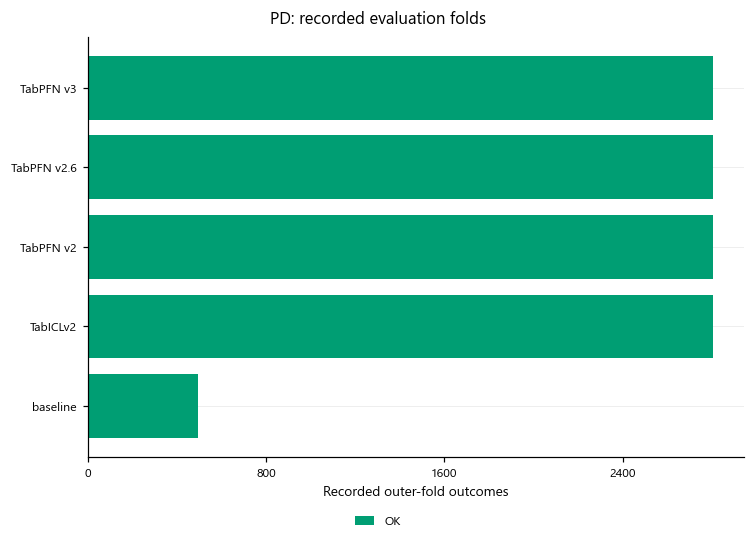

PD. Recorded outer-fold outcomes by model group. This counts records rather than inferring completion from missing files. Subsequent effects require all configured outer folds for each model–dataset cell and its matching untuned control.

In [2]:
run = cp.load_campaign(1, TRACK)
report.table('Available evidence', pub.availability(run))
cp.show(sink, cp.plot_eval_coverage(run), track=run.track)
report.add('1. Evidence and benchmark eligibility', cp.coverage_summary(run))

## 2. Initial and post-finetuning monitoring scores

A configuration is one combination of base, learning rate, anchoring and adaptation. One dashboard averages the four partition means; a second retains individual training partitions. Scores are AUC for PD and R² for LGD.

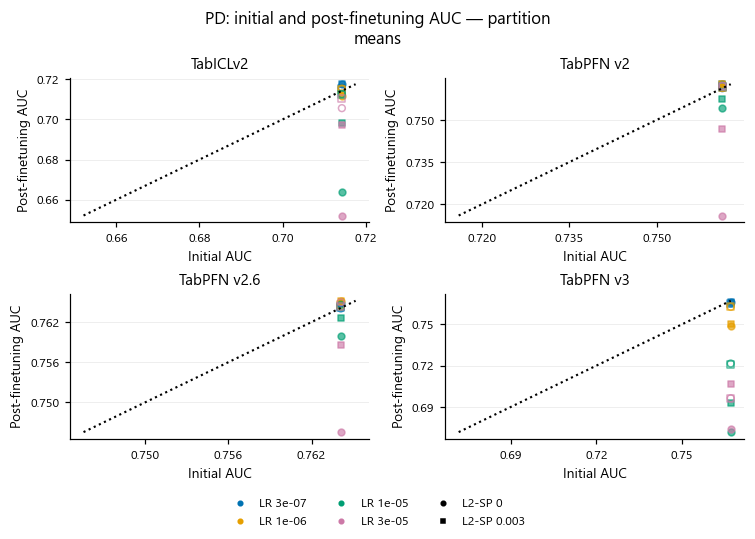

PD. Initial and post-finetuning scores for each completed configuration. Each dot averages the four partition means with equal partition weight; incomplete configurations are omitted. Scores first average available held-out tables within each partition. Colors distinguish learning rates and marker shapes distinguish anchoring. Open marks freeze the transformer backbone; filled marks update all parameters. The diagonal indicates unchanged score. These fixed-context monitors do not substitute for final five-fold benchmark scores.

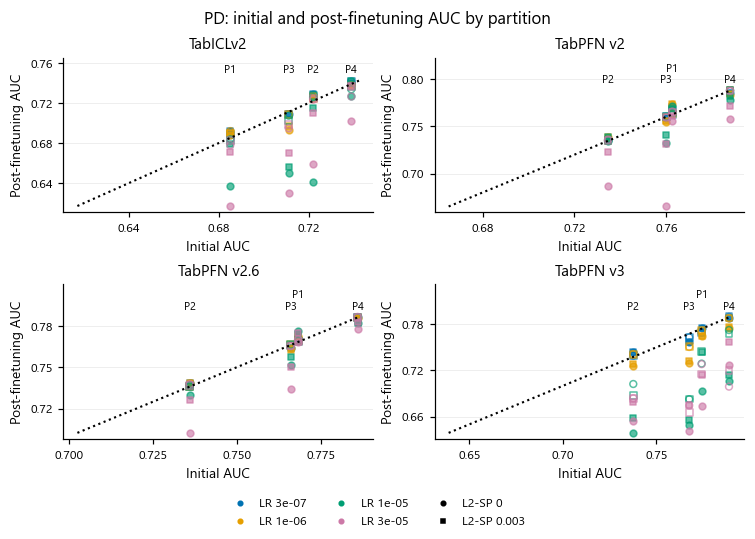

PD. Initial and post-finetuning scores for each completed configuration. Labels P1–P4 above the point columns identify training-dataset partitions; each configuration retains its own point. Scores first average available held-out tables within each partition. Colors distinguish learning rates and marker shapes distinguish anchoring. Open marks freeze the transformer backbone; filled marks update all parameters. The diagonal indicates unchanged score. These fixed-context monitors do not substitute for final five-fold benchmark scores.

,trial,updates,processed_rows,dataset,value,initial,effect,base,learning_rate,l2sp_lambda,frozen,sampling,partition,seed
5,cpt_main_v5_s00_pd_tabicl-classifier-v2-202602...,10000,195157151,Thomas,0.634328,0.606713,0.027615,TabICLv2,1.000000e-05,0.003,False,one_sample,0,42
11,cpt_main_v5_s00_pd_tabicl-classifier-v2-202602...,10000,195157151,Thomas,0.600142,0.606713,-0.006571,TabICLv2,1.000000e-05,0.003,True,one_sample,0,42
17,cpt_main_v5_s00_pd_tabicl-classifier-v2-202602...,10000,195157151,Thomas,0.561726,0.606713,-0.044987,TabICLv2,1.000000e-05,0.000,False,one_sample,0,42
23,cpt_main_v5_s00_pd_tabicl-classifier-v2-202602...,10000,195157151,Thomas,0.605317,0.606713,-0.001396,TabICLv2,1.000000e-05,0.000,True,one_sample,0,42
29,cpt_main_v5_s00_pd_tabicl-classifier-v2-202602...,10000,195157151,Thomas,0.600614,0.606713,-0.006098,TabICLv2,1.000000e-06,0.003,False,one_sample,0,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6503,cpt_main_v5_s03_pd_tabpfn-v3-classifier-v3_def...,10000,191675495,SBA Loans Case,0.984852,0.989956,-0.005104,TabPFN v3,3.000000e-05,0.000,True,one_sample,3,42
6509,cpt_main_v5_s03_pd_tabpfn-v3-classifier-v3_def...,10000,191675495,SBA Loans Case,0.989586,0.989956,-0.000370,TabPFN v3,3.000000e-07,0.003,False,one_sample,3,42
6515,cpt_main_v5_s03_pd_tabpfn-v3-classifier-v3_def...,10000,191675495,SBA Loans Case,0.989778,0.989956,-0.000178,TabPFN v3,3.000000e-07,0.003,True,one_sample,3,42
6521,cpt_main_v5_s03_pd_tabpfn-v3-classifier-v3_def...,10000,191675495,SBA Loans Case,0.989629,0.989956,-0.000327,TabPFN v3,3.000000e-07,0.000,False,one_sample,3,42


In [3]:
cp.show(sink, db.plot_endpoints(run), track=run.track)
cp.show(sink, db.plot_endpoints(run, by_partition=True), track=run.track)
report.table('All per-table monitoring endpoints', db.monitor_observations(run).query('updates == @run.target') if not run.trajectories.empty else run.trajectories)
report.add('2. Initial and post-finetuning monitoring scores', 'Open marks freeze the backbone; filled marks update all normally trainable parameters. Colors denote learning rates and marker shapes denote L2-SP. These are fixed-context monitoring scores, not final five-fold estimates.')

## 3. Aggregate effects of adaptation choices

Combine the four bases when displaying conditional effects of anchoring, freezing and learning rate. Base-model means summarize adaptation relative to each model’s own starting weights.

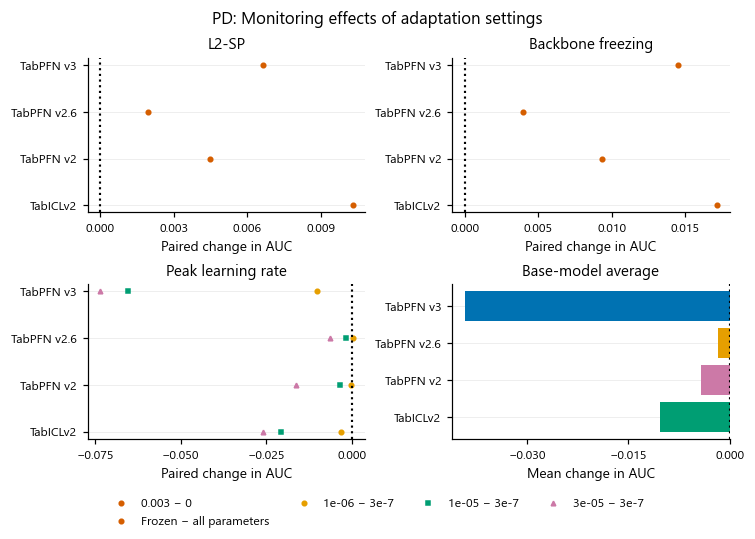

PD. Conditional differences match dataset and every other configuration setting before averaging within model. Peak-learning-rate contrasts use LR 3e-7 as reference. The base-model panel averages configuration effects relative to each model's own initialization; it is descriptive rather than a causal architecture contrast. Positive values favor the alternative setting. Dataset and configuration support are retained in the accompanying tables.

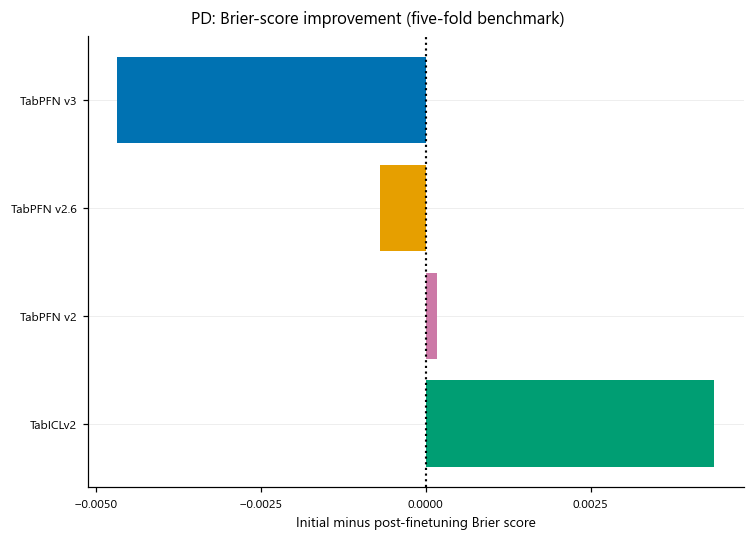

PD. Brier-score reductions from five-fold benchmark, averaged with equal weight over observed configuration–dataset pairs. Positive values indicate better probability accuracy. Brier score combines calibration and discrimination; it is not a pure calibration metric. Missing comparisons are omitted, with support counts reported.

In [4]:
cp.show(sink, db.plot_endpoint_factors(run), track=run.track)
cp.show(sink, db.plot_brier(run), track=run.track)
report.add('3. Aggregate effects of adaptation choices', 'Match every other setting and dataset before averaging contrasts. Base averages are descriptive, not causal model comparisons. Probability accuracy is assessed by Brier score when paired measurements exist; missing measurements are not inferred.')

## 4. Final held-out benchmark effects

The checkpoint weights are fixed. Context rows come from each outer training fold; threshold and calibration selection use disjoint inner validation rows.

,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,Bondora Peer-to-Peer,0.897214,0.888418,-0.008795,-0.008795,Bondora Peer-to-Peer,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.008795,42
1,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,Cobranded,0.842771,0.839247,-0.003524,-0.003524,Cobranded,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.003524,42
2,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,Credit Risk,0.955142,0.926268,-0.028874,-0.028874,Credit Risk,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.028874,42
3,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,GMSC,0.867187,0.860626,-0.006561,-0.006561,GMSC,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.006561,42
4,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,German Credit,0.790140,0.688480,-0.101660,-0.101660,German Credit,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.101660,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1083,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,PropPD2,0.657296,0.659203,0.001907,0.001907,PropPD2,TabPFN v3,3.000000e-07,True,0.0,one_sample,0.001907,42
1084,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,SBA Loans Case,0.989833,0.990338,0.000505,0.000505,SBA Loans Case,TabPFN v3,3.000000e-07,True,0.0,one_sample,0.000505,42
1085,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,Taiwan Credit Card,0.789665,0.790003,0.000338,0.000338,Taiwan Credit Card,TabPFN v3,3.000000e-07,True,0.0,one_sample,0.000338,42
1086,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,Thomas,0.651588,0.653203,0.001615,0.001615,Thomas,TabPFN v3,3.000000e-07,True,0.0,one_sample,0.001615,42


,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,Bondora Peer-to-Peer,0.897214,0.888418,-0.008795,-0.008795,Bondora Peer-to-Peer,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.008795,42
1,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,Cobranded,0.842771,0.839247,-0.003524,-0.003524,Cobranded,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.003524,42
2,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,Credit Risk,0.955142,0.926268,-0.028874,-0.028874,Credit Risk,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.028874,42
3,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,GMSC,0.867187,0.860626,-0.006561,-0.006561,GMSC,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.006561,42
4,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,German Credit,0.790140,0.688480,-0.101660,-0.101660,German Credit,TabICLv2,1.000000e-05,False,0.0,one_sample,-0.101660,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1083,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,PropPD2,0.657296,0.659203,0.001907,0.001907,PropPD2,TabPFN v3,3.000000e-07,True,0.0,one_sample,0.001907,42
1084,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,SBA Loans Case,0.989833,0.990338,0.000505,0.000505,SBA Loans Case,TabPFN v3,3.000000e-07,True,0.0,one_sample,0.000505,42
1085,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,Taiwan Credit Card,0.789665,0.790003,0.000338,0.000338,Taiwan Credit Card,TabPFN v3,3.000000e-07,True,0.0,one_sample,0.000338,42
1086,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,Thomas,0.651588,0.653203,0.001615,0.001615,Thomas,TabPFN v3,3.000000e-07,True,0.0,one_sample,0.001615,42


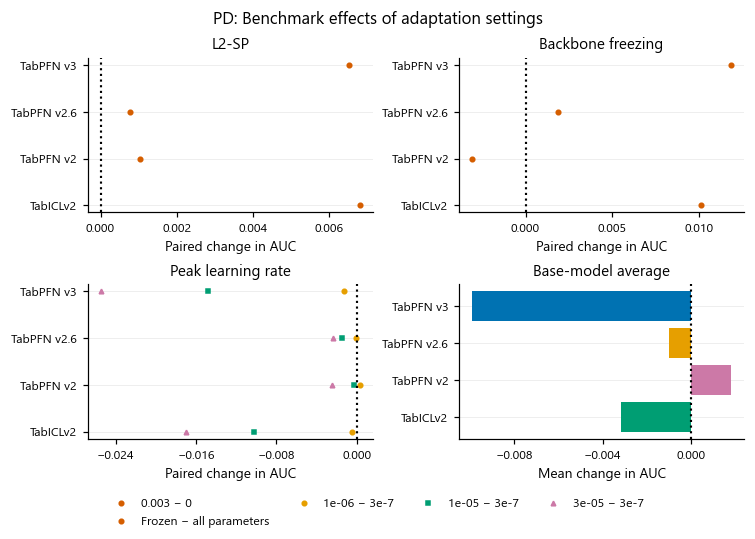

PD. Conditional differences match dataset and every other configuration setting before averaging within model. Peak-learning-rate contrasts use LR 3e-7 as reference. The base-model panel averages configuration effects relative to each model's own initialization; it is descriptive rather than a causal architecture contrast. Positive values favor the alternative setting. Dataset and configuration support are retained in the accompanying tables.

In [5]:
endpoint = cp.benchmark_effects(run)
report.table('Complete primary benchmark dataset effects', endpoint)
report.table('Complete AUC or R² benchmark dataset effects', cp.benchmark_effects(run, db.monitor_metric(run)))
cp.show(sink, db.plot_endpoint_factors(run, benchmark=True), track=run.track)
report.add('4. Final held-out benchmark effects', cp.effect_summary(endpoint) + '\nLGD primary benchmark error remains RMSE; R² is also reported. Five outer folds are averaged within table before cross-table comparisons.')

## 5. Probability quality, calibration and thresholds

Secondary metrics assess complementary properties. Calibration and F1 thresholds are chosen on validation rows, never on the outer test labels.

Saved raw test predictions additionally measure systematic over/underprediction and paired prediction changes. These diagnostics describe observed errors; they do not identify theoretical bias or context variance.


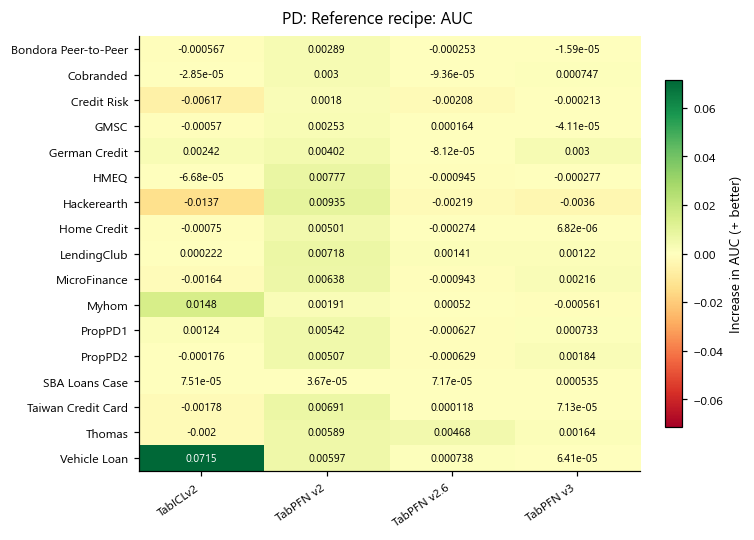

PD. Dataset-level AUC changes for the predefined full-update recipe, LR 3e-7 and L2-SP 0.003, relative to each model's untuned weights. Pairing occurs within outer folds and requires all five folds. Positive values indicate improvement; only RMSE is expressed as a fractional reduction. 

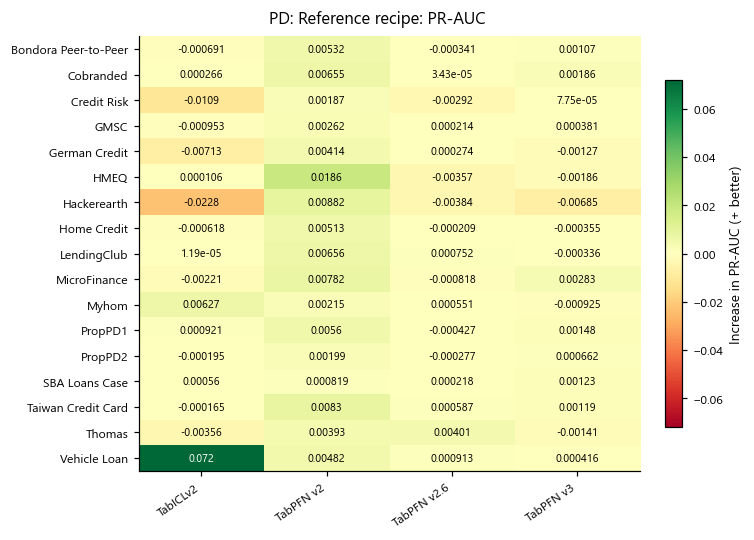

PD. Dataset-level PR-AUC changes for the predefined full-update recipe, LR 3e-7 and L2-SP 0.003, relative to each model's untuned weights. Pairing occurs within outer folds and requires all five folds. Positive values indicate improvement; only RMSE is expressed as a fractional reduction. 

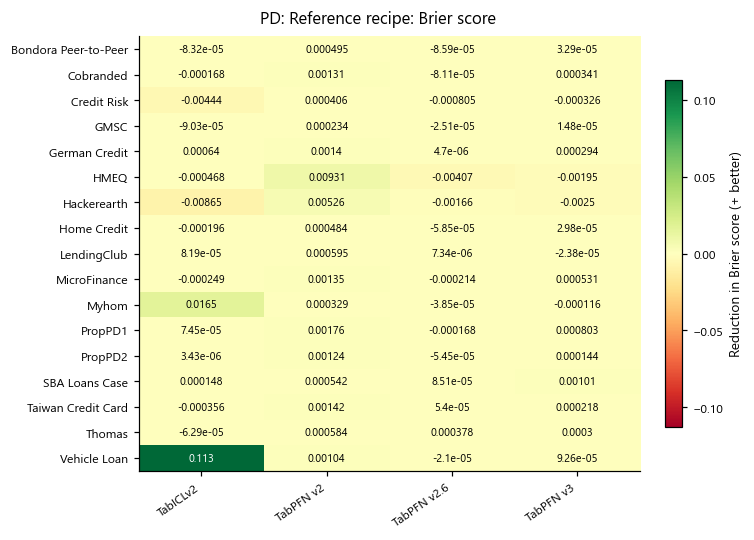

PD. Dataset-level Brier score changes for the predefined full-update recipe, LR 3e-7 and L2-SP 0.003, relative to each model's untuned weights. Pairing occurs within outer folds and requires all five folds. Positive values indicate improvement; only RMSE is expressed as a fractional reduction. Brier scores assess probabilistic accuracy, combining calibration and discrimination.

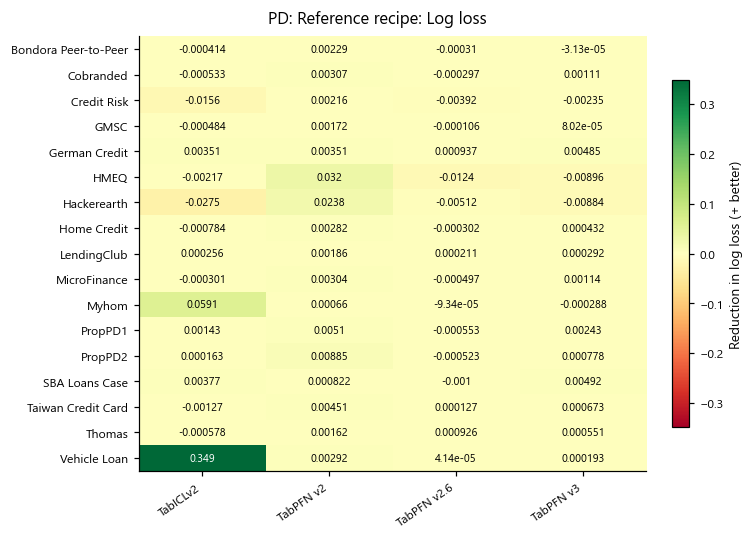

PD. Dataset-level Log loss changes for the predefined full-update recipe, LR 3e-7 and L2-SP 0.003, relative to each model's untuned weights. Pairing occurs within outer folds and requires all five folds. Positive values indicate improvement; only RMSE is expressed as a fractional reduction. Log loss assesses predicted probabilities and penalizes confidently incorrect predictions.

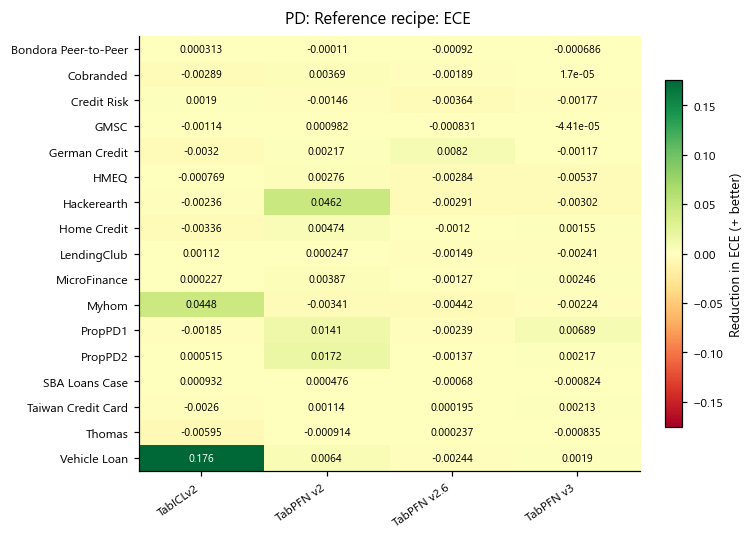

PD. Dataset-level ECE changes for the predefined full-update recipe, LR 3e-7 and L2-SP 0.003, relative to each model's untuned weights. Pairing occurs within outer folds and requires all five folds. Positive values indicate improvement; only RMSE is expressed as a fractional reduction. ECE is a bin-dependent calibration diagnostic, not a complete measure of probabilistic accuracy.

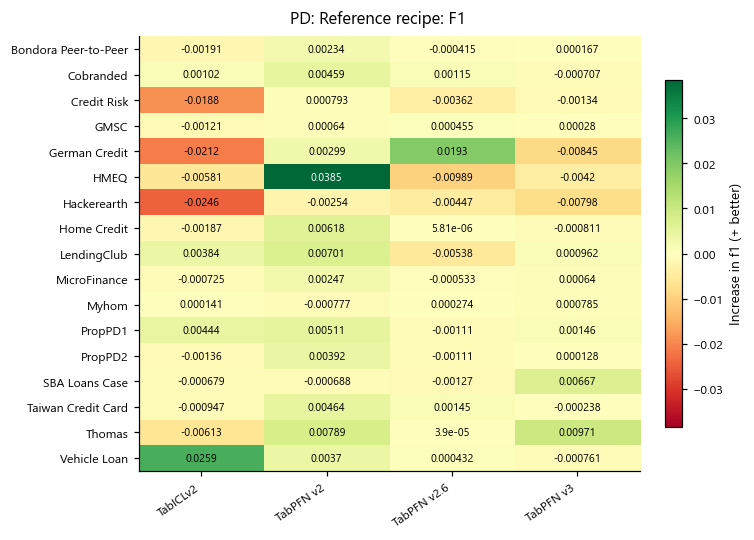

PD. Dataset-level F1 changes for the predefined full-update recipe, LR 3e-7 and L2-SP 0.003, relative to each model's untuned weights. Pairing occurs within outer folds and requires all five folds. Positive values indicate improvement; only RMSE is expressed as a fractional reduction. F1 uses thresholds chosen on inner validation rows.

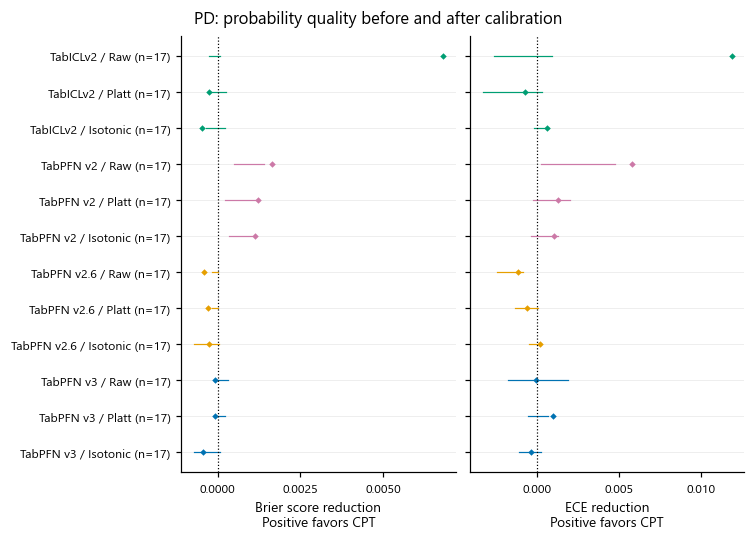

PD. Changes in outer-test Brier score and expected calibration error (ECE) for the predefined full-update reference (LR 3e-7, L2-SP 0.003, one-sample training) relative to its untuned base. Positive reductions favor continued pretraining (CPT). Raw probabilities and validation-fitted Platt and isotonic calibration use a common dataset cohort within each base: all six scores require the same five completed, matched outer folds. Diamonds show equal-dataset means; horizontal lines span dataset quartiles, not confidence intervals. ECE depends on the binning scheme.

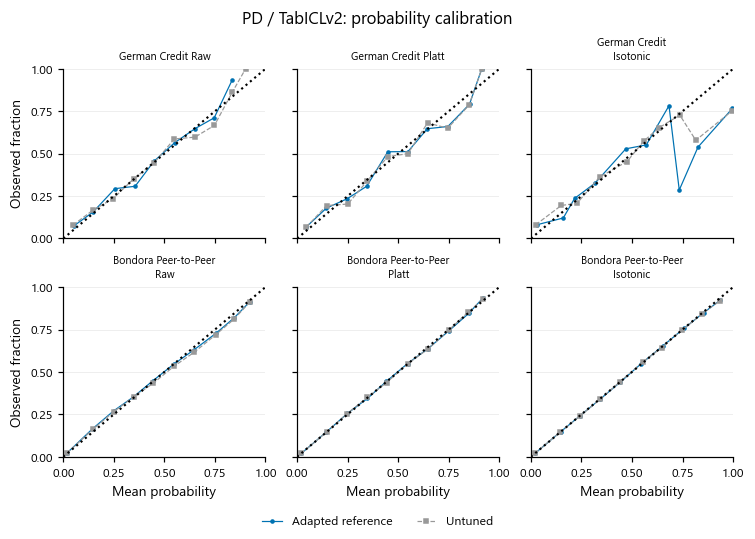

PD. Raw, Platt-scaled and isotonic positive-class reliability for the predefined full-update reference (LR 3e-7, L2-SP 0.003, one-sample training) and its untuned base. Rows identify datasets and columns identify calibration methods. Each populated panel requires bin records from the same five completed outer folds for both models; missing panels are labeled. Ten equal-width bins pool outer-test counts within the dataset; empty bins are omitted and bin counts are retained in the text summary. Calibrators are fitted only on inner validation rows. The diagonal denotes agreement of predicted and observed probabilities; these curves have no uncertainty intervals. Examples are chosen at evenly spaced dataset-size ranks (smallest and largest when two are shown), using total outer-test row counts independently of model scores. They illustrate calibration shapes rather than the typical treatment effect. 

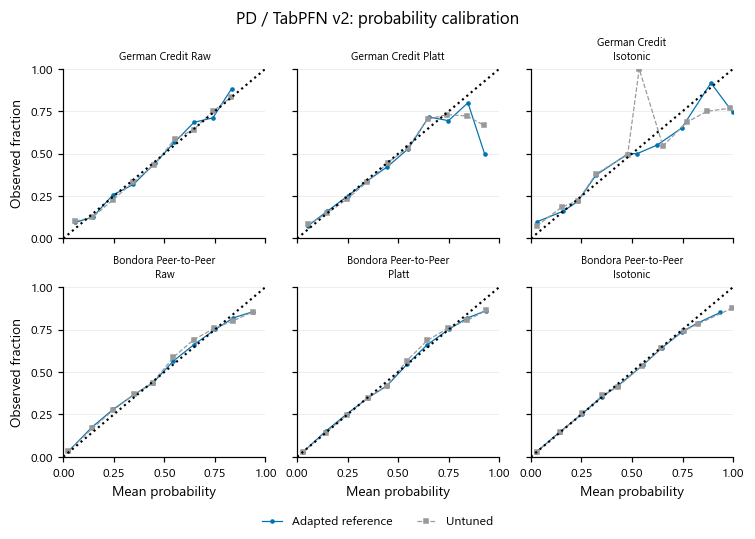

PD. Raw, Platt-scaled and isotonic positive-class reliability for the predefined full-update reference (LR 3e-7, L2-SP 0.003, one-sample training) and its untuned base. Rows identify datasets and columns identify calibration methods. Each populated panel requires bin records from the same five completed outer folds for both models; missing panels are labeled. Ten equal-width bins pool outer-test counts within the dataset; empty bins are omitted and bin counts are retained in the text summary. Calibrators are fitted only on inner validation rows. The diagonal denotes agreement of predicted and observed probabilities; these curves have no uncertainty intervals. Examples are chosen at evenly spaced dataset-size ranks (smallest and largest when two are shown), using total outer-test row counts independently of model scores. They illustrate calibration shapes rather than the typical treatment effect. 

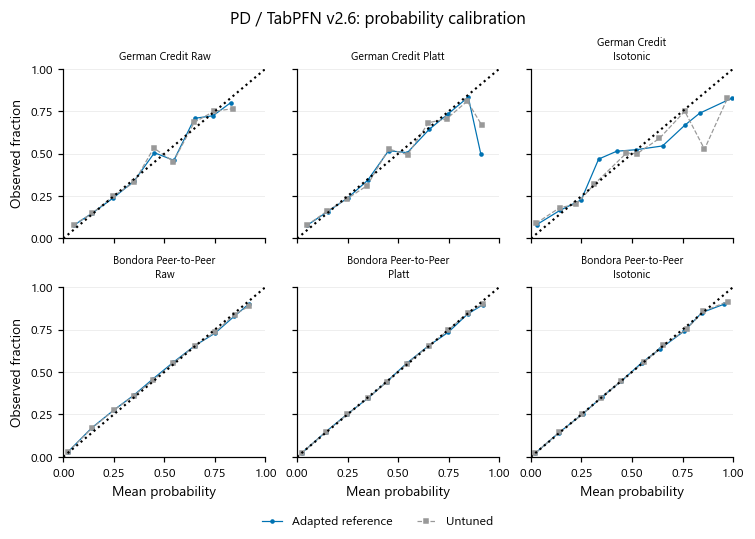

PD. Raw, Platt-scaled and isotonic positive-class reliability for the predefined full-update reference (LR 3e-7, L2-SP 0.003, one-sample training) and its untuned base. Rows identify datasets and columns identify calibration methods. Each populated panel requires bin records from the same five completed outer folds for both models; missing panels are labeled. Ten equal-width bins pool outer-test counts within the dataset; empty bins are omitted and bin counts are retained in the text summary. Calibrators are fitted only on inner validation rows. The diagonal denotes agreement of predicted and observed probabilities; these curves have no uncertainty intervals. Examples are chosen at evenly spaced dataset-size ranks (smallest and largest when two are shown), using total outer-test row counts independently of model scores. They illustrate calibration shapes rather than the typical treatment effect. 

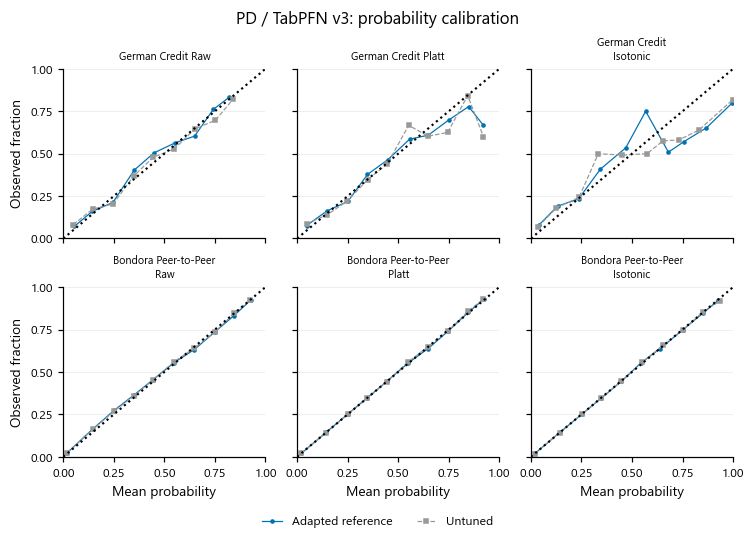

PD. Raw, Platt-scaled and isotonic positive-class reliability for the predefined full-update reference (LR 3e-7, L2-SP 0.003, one-sample training) and its untuned base. Rows identify datasets and columns identify calibration methods. Each populated panel requires bin records from the same five completed outer folds for both models; missing panels are labeled. Ten equal-width bins pool outer-test counts within the dataset; empty bins are omitted and bin counts are retained in the text summary. Calibrators are fitted only on inner validation rows. The diagonal denotes agreement of predicted and observed probabilities; these curves have no uncertainty intervals. Examples are chosen at evenly spaced dataset-size ranks (smallest and largest when two are shown), using total outer-test row counts independently of model scores. They illustrate calibration shapes rather than the typical treatment effect. 

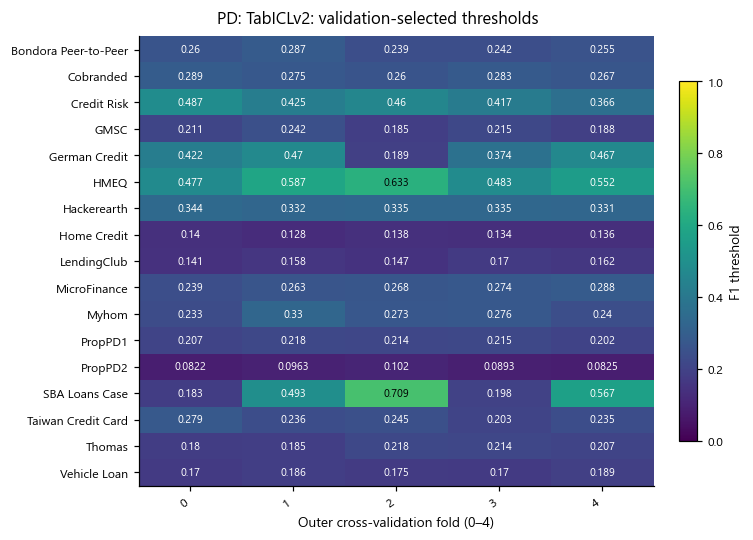

PD. F1-maximizing thresholds selected separately on each inner validation split for the predefined reference recipe. The displayed dataset rows have all five completed outer folds. Outer-test labels never choose thresholds, and threshold variation is not itself evidence of poor discrimination.

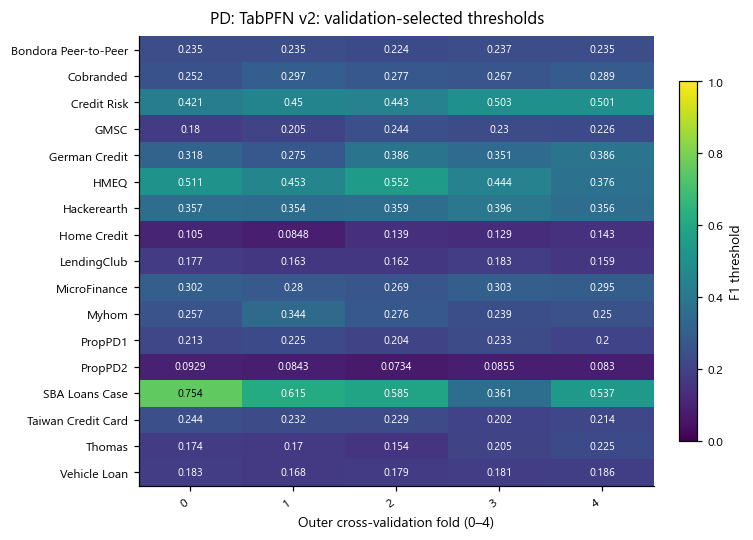

PD. F1-maximizing thresholds selected separately on each inner validation split for the predefined reference recipe. The displayed dataset rows have all five completed outer folds. Outer-test labels never choose thresholds, and threshold variation is not itself evidence of poor discrimination.

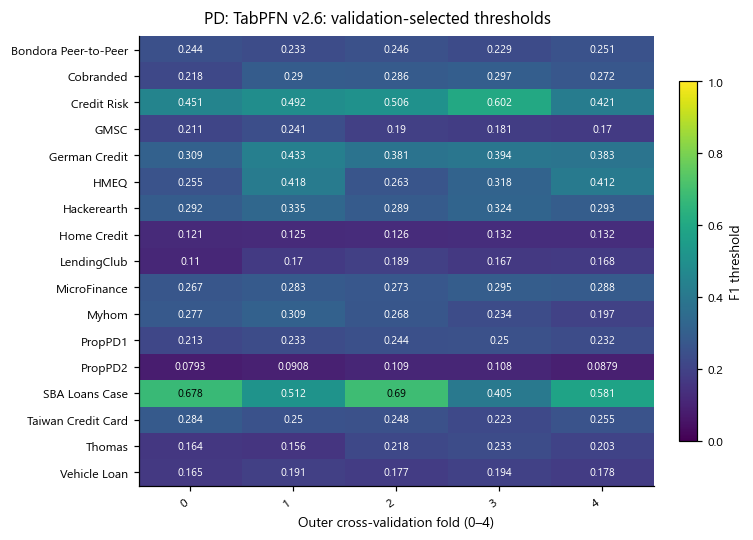

PD. F1-maximizing thresholds selected separately on each inner validation split for the predefined reference recipe. The displayed dataset rows have all five completed outer folds. Outer-test labels never choose thresholds, and threshold variation is not itself evidence of poor discrimination.

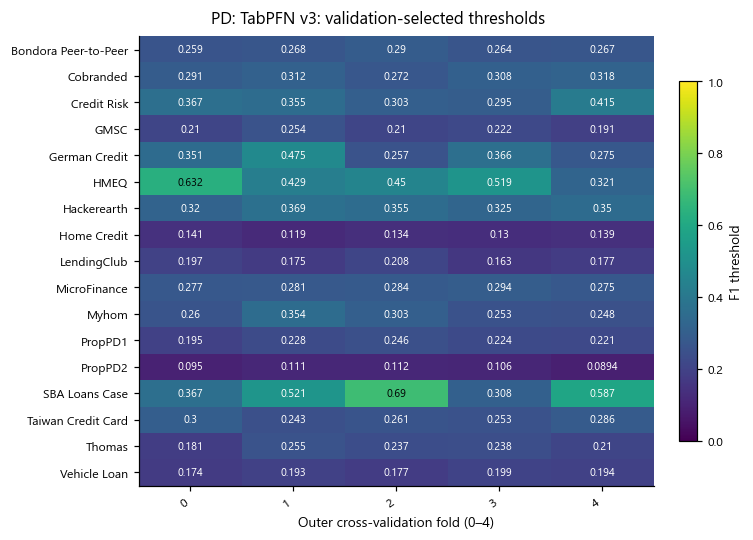

PD. F1-maximizing thresholds selected separately on each inner validation split for the predefined reference recipe. The displayed dataset rows have all five completed outer folds. Outer-test labels never choose thresholds, and threshold variation is not itself evidence of poor discrimination.

,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,Reference CPT,verified,"Five folds; matched row identities, targets an..."
...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,verified,"Five folds; matched row identities, targets an..."
64,TabPFN v3,Cobranded,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
65,TabPFN v3,Home Credit,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
66,TabPFN v3,LendingClub,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,730176,0.138105,0.135123,0.132569,-0.002982,-0.005536,-0.002554,0.080536,0.080619,-0.000083,-0.002554,0.019772,0.009558
1,TabICLv2,HMEQ,0,Reference CPT,5960,0.199497,0.190717,0.192194,-0.008779,-0.007303,0.001476,0.017686,0.018154,-0.000468,0.001476,0.034721,0.011352
2,TabICLv2,MicroFinance,0,Reference CPT,158700,0.378091,0.364956,0.364263,-0.013134,-0.013828,-0.000693,0.218164,0.218413,-0.000249,-0.000693,0.028269,0.021001
3,TabICLv2,Thomas,0,Reference CPT,1225,0.263673,0.247090,0.244012,-0.016584,-0.019662,-0.003078,0.183083,0.183146,-0.000063,-0.003078,0.014727,0.010257
4,TabICLv2,GMSC,1,Reference CPT,150000,0.066840,0.057865,0.056626,-0.008975,-0.010214,-0.001239,0.049076,0.049166,-0.000090,-0.001239,0.007366,0.003548
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,105471,0.092755,0.075083,0.077348,-0.017673,-0.015407,0.002265,0.082365,0.082222,0.000144,0.002265,0.007568,0.005367
64,TabPFN v3,Cobranded,3,Reference CPT,80000,0.246213,0.234716,0.236553,-0.011496,-0.009659,0.001837,0.130932,0.130591,0.000341,0.001837,0.017345,0.009891
65,TabPFN v3,Home Credit,3,Reference CPT,307511,0.080729,0.066750,0.068345,-0.013979,-0.012384,0.001595,0.068395,0.068366,0.000030,0.001595,0.009478,0.005742
66,TabPFN v3,LendingClub,3,Reference CPT,9578,0.160054,0.140981,0.138785,-0.019073,-0.021269,-0.002196,0.126388,0.126412,-0.000024,-0.002196,0.011739,0.008609


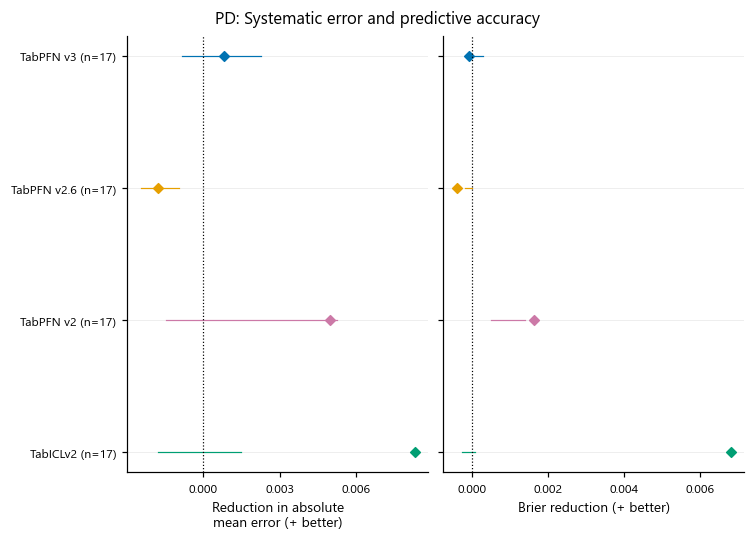

PD. Matched five-fold out-of-fold predictions on held-out credit tables. Diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

In [6]:
cp.show(sink, pub.plot_metric_profile(run), track=run.track)
cp.show(sink, dg.plot_calibration_overview(run), track=run.track)
cp.show(sink, dg.plot_reliability(run, max_datasets=style.CALIBRATION_EXAMPLE_TABLES), track=run.track)
cp.show(sink, pub.plot_thresholds(run), track=run.track)
prediction_values, prediction_coverage = pred.analyze(run, reference=True)
report.table('Saved prediction coverage: fixed reference', prediction_coverage)
report.table('Paired per-table prediction diagnostics: fixed reference', prediction_values)
cp.show(sink, pred.plot_diagnostics(prediction_values, TRACK, coverage=prediction_coverage), track=TRACK)
report.add('5. Probability quality, calibration and thresholds', 'Brier score combines discrimination and calibration; ECE depends on its bins. The calibration overview compares the same tables across raw, Platt and isotonic scores; reliability examples are selected by dataset size independently of performance.' + '\n' + pred.NOTE)


## 6. Classical controls, non-credit retention and cost

Untuned and classical controls contextualize adaptation. The retention panel remains separate from the credit corpus.

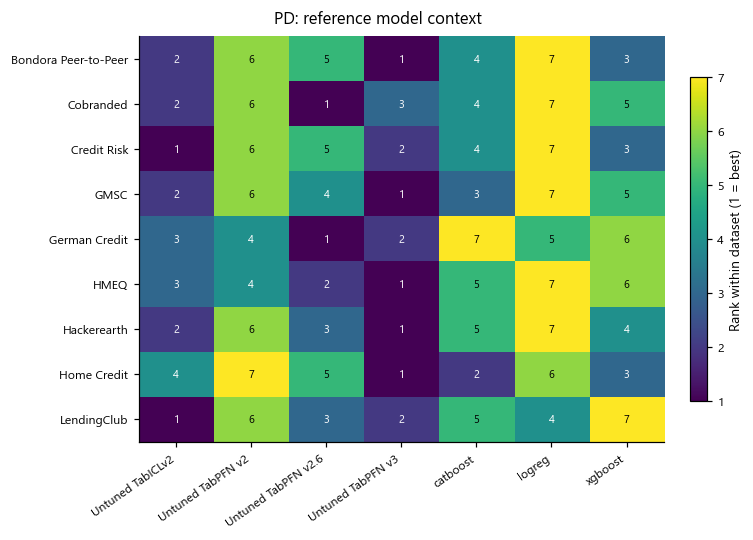

PD. Within-dataset ranks of untuned foundation models and classical controls, using complete outer-fold mean scores. Only datasets with every displayed control are included. Ranks provide corpus context; they do not quantify the size of the continued-pretraining effect.

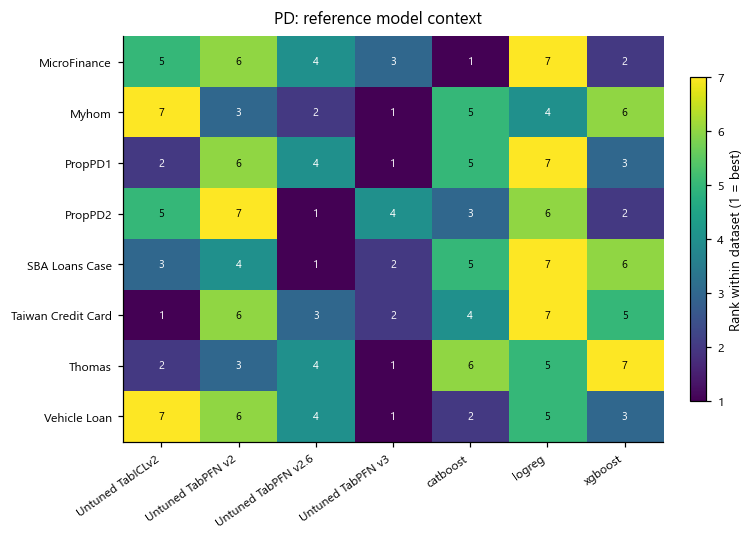

PD. Within-dataset ranks of untuned foundation models and classical controls, using complete outer-fold mean scores. Only datasets with every displayed control are included. Ranks provide corpus context; they do not quantify the size of the continued-pretraining effect.

,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,openml_46905,0.845725,0.800068,-0.045657,-0.045657,openml_46905,TabICLv2,1.000000e-05,False,0.000,one_sample,-0.045657,42
1,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,openml_46947,0.936708,0.920753,-0.015955,-0.015955,openml_46947,TabICLv2,1.000000e-05,False,0.000,one_sample,-0.015955,42
2,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,openml_46952,0.940093,0.901680,-0.038413,-0.038413,openml_46952,TabICLv2,1.000000e-05,False,0.000,one_sample,-0.038413,42
3,tabicl-trained__tabicl-v2__lr1e-05__l2sp0,TabICLv2,openml_46956,0.767514,0.656727,-0.110787,-0.110787,openml_46956,TabICLv2,1.000000e-05,False,0.000,one_sample,-0.110787,42
4,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46905,0.845725,0.829112,-0.016613,-0.016613,openml_46905,TabICLv2,1.000000e-05,False,0.003,one_sample,-0.016613,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,tabpfn-trained__v3-default__lr3e-07__l2sp0.003...,v3-default,openml_46956,0.776054,0.776159,0.000105,0.000105,openml_46956,TabPFN v3,3.000000e-07,True,0.003,one_sample,0.000105,42
252,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,openml_46905,0.841379,0.846471,0.005092,0.005092,openml_46905,TabPFN v3,3.000000e-07,True,0.000,one_sample,0.005092,42
253,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,openml_46947,0.937855,0.937919,0.000064,0.000064,openml_46947,TabPFN v3,3.000000e-07,True,0.000,one_sample,0.000064,42
254,tabpfn-trained__v3-default__lr3e-07__l2sp0__fr...,v3-default,openml_46952,0.936632,0.937233,0.000601,0.000601,openml_46952,TabPFN v3,3.000000e-07,True,0.000,one_sample,0.000601,42


,"('elapsed_sec', 'count')","('elapsed_sec', 'median')","('elapsed_sec', 'min')","('elapsed_sec', 'max')","('sec_per_step', 'count')","('sec_per_step', 'median')","('sec_per_step', 'min')","('sec_per_step', 'max')","('peak_gpu_gb', 'count')","('peak_gpu_gb', 'median')",...,"('rows_seen', 'min')","('rows_seen', 'max')","('trainable_params', 'count')","('trainable_params', 'median')","('trainable_params', 'min')","('trainable_params', 'max')","('final_drift', 'count')","('final_drift', 'median')","('final_drift', 'min')","('final_drift', 'max')"
"('TabICLv2', False)",32,5880.051329,5388.954923,6227.217700,32,0.588005,0.538895,0.622722,32,27.1190,...,168231937,195157151,32,27552250.0,27552250,27552250,32,0.003687,0.001127,0.028629
"('TabICLv2', True)",32,5641.459922,5191.705577,5953.787302,32,0.564146,0.519171,0.595379,32,26.7075,...,168231937,195157151,32,1818106.0,1818106,1818106,32,0.006402,0.001463,0.042363
"('TabPFN v2', False)",32,4989.562487,4558.125119,5434.754171,32,0.498956,0.455813,0.543475,32,181.0705,...,74887937,84373151,32,7244554.0,7244554,7244554,32,0.004249,0.001053,0.028788
"('TabPFN v2', True)",32,4818.276219,4399.349810,5211.900758,32,0.481828,0.439935,0.521190,32,108.1805,...,74887937,84373151,32,166666.0,166666,166666,32,0.006800,0.001252,0.078394
"('TabPFN v2.6', False)",32,4264.081141,3931.728692,4570.578204,32,0.426408,0.393173,0.457058,32,128.4200,...,80721937,91297151,32,10732042.0,10732042,10732042,32,0.003833,0.000877,0.040765
"('TabPFN v2.6', True)",32,3799.214932,3556.330243,4103.147097,32,0.379921,0.355633,0.410315,32,80.4470,...,80721937,91297151,32,101386.0,101386,101386,32,0.001670,0.000229,0.015853
"('TabPFN v3', False)",32,5222.860977,4837.436067,5610.246155,32,0.522286,0.483744,0.561025,32,121.0455,...,168231937,195157151,32,53153136.0,53153136,53153136,32,0.006299,0.001484,0.052170
"('TabPFN v3', True)",32,4818.272543,4506.762127,5040.165402,32,0.481827,0.450676,0.504017,32,109.9990,...,168231937,195157151,32,1795440.0,1795440,1795440,32,0.006421,0.001305,0.037843


In [7]:
cp.show(sink, cp.plot_control_context(run), track=run.track)
report.table('Non-credit benchmark dataset effects', cp.benchmark_effects(run, domain='noncredit'))
report.table('Completed-trial computational cost', pub.cost_summary(run))
report.add('6. Classical controls, non-credit retention and cost', 'One main training seed and overlapping adaptation corpora limit independence claims. The non-credit panel is finite and original pretraining overlap is unverified. No recipe winner is treated as an unbiased estimate of future generalization.')

## Complete text summary

Every displayed numerical value and caption, in section order.

In [8]:
print(report.summary(sink))

Experiment 1: PD outcomes and evaluation

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.

1. Evidence and benchmark eligibility
Run cpt_main_v5; PD; 256 planned trials; target 10,000 successful updates.
status
OK    256
1536 trajectory records; 11715 benchmark fold records.
PENDING means no recorded outcome; it can include running or queued work. This is not live scheduler state.

Table: Available evidence
CSV (first column: row index)
row,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,201472,Project training diagnostics
3,Milestone rows,1536,Project traj